<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Random_Forest/churn_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print('Rows, columns:', df.shape)
print()
print('Churn counts:')
print(df['Churn'].value_counts())
print('Share who churned:', round((df['Churn'] == 'Yes').mean(), 3))
print()

total_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank_rows = df[total_numeric.isna()]
print('Data type of TotalCharges:', df['TotalCharges'].dtype)
print('Rows where TotalCharges is blank or not a number:', len(blank_rows))
print(blank_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']].head().to_string(index=False))

Rows, columns: (7043, 21)

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Share who churned: 0.265

Data type of TotalCharges: object
Rows where TotalCharges is blank or not a number: 11
customerID  tenure  MonthlyCharges TotalCharges
4472-LVYGI       0           52.55             
3115-CZMZD       0           20.25             
5709-LVOEQ       0           80.85             
4367-NUYAO       0           25.75             
1371-DWPAZ       0           56.05             


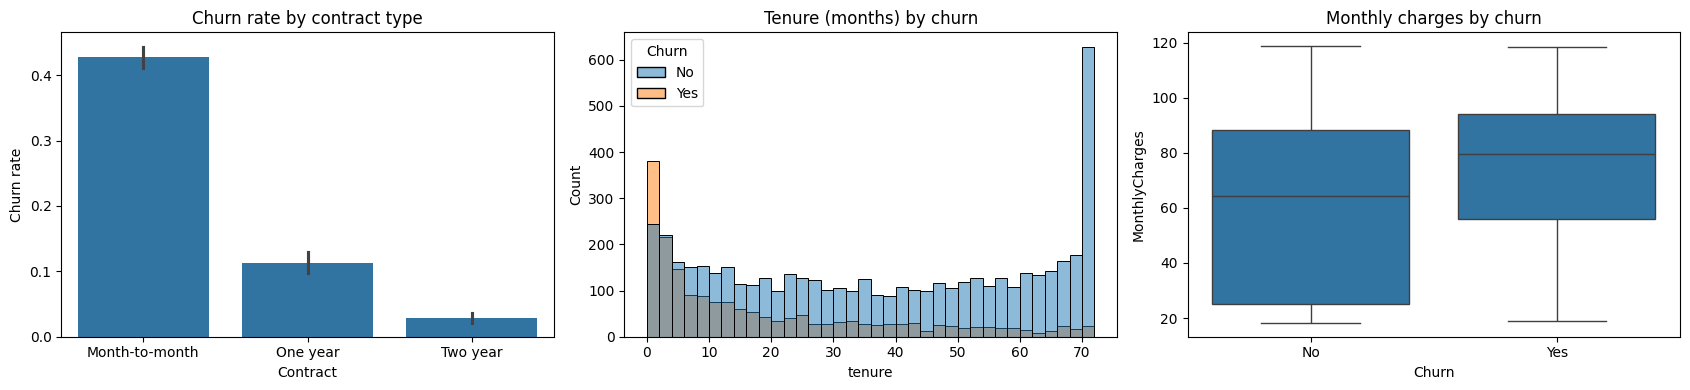

In [3]:
viz = df.assign(Churned=(df['Churn'] == 'Yes').astype(int))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.barplot(x='Contract', y='Churned', data=viz,
            order=['Month-to-month', 'One year', 'Two year'], ax=axes[0])
axes[0].set_title('Churn rate by contract type')
axes[0].set_ylabel('Churn rate')

sns.histplot(data=viz, x='tenure', hue='Churn', bins=36, multiple='layer', alpha=0.5, ax=axes[1])
axes[1].set_title('Tenure (months) by churn')

sns.boxplot(x='Churn', y='MonthlyCharges', data=viz, ax=axes[2])
axes[2].set_title('Monthly charges by churn')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
              'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
              'Contract', 'PaymentMethod']


def preprocess(raw):
    out = raw.copy()
    out['TotalCharges'] = pd.to_numeric(out['TotalCharges'], errors='coerce').fillna(0)
    out = out.drop(columns=['customerID', 'Churn'], errors='ignore')
    for col in ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']:
        out[col] = out[col].map({'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0})
    return out


def encode(raw, columns=None):
    X_enc = pd.get_dummies(preprocess(raw), columns=multi_cols, dtype=int)
    if columns is not None:
        # make a new customer's table line up exactly with the training columns
        X_enc = X_enc.reindex(columns=columns, fill_value=0)
    return X_enc


y = (df['Churn'] == 'Yes').astype(int)     # 1 = churned
X = encode(df)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Features:', X.shape[1], '| Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Missing values left:', int(X.isnull().sum().sum()))
print('Churn rate  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))
X_train.head()

Features: 40 | Training rows: 5634 | Test rows: 1409
Missing values left: 0
Churn rate  train: 0.265  test: 0.265


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,1,0,0,0,35,0,0,49.20,1701.65,0,...,0,0,1,1,0,0,0,0,1,0
3151,1,0,1,1,15,1,0,75.10,1151.55,1,...,1,0,0,1,0,0,0,0,0,1
4860,1,0,1,1,13,0,0,40.55,590.35,0,...,1,0,0,0,0,1,0,0,0,1
3867,0,0,1,0,26,1,1,73.50,1905.70,1,...,0,0,1,0,0,1,0,1,0,0
3810,1,0,1,1,1,1,0,44.55,44.55,1,...,1,0,0,1,0,0,0,0,1,0


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score

models = {
    'Baseline (always stays)': DummyClassifier(strategy='most_frequent'),
    'Single decision tree': DecisionTreeClassifier(random_state=42),
    'Random forest (200 trees)': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    rows.append({
        'model': name,
        'train accuracy': m.score(X_train, y_train),
        'test accuracy': accuracy_score(y_test, m.predict(X_test)),
        'test ROC-AUC': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
        'churn recall': recall_score(y_test, m.predict(X_test), zero_division=0),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

                    model  train accuracy  test accuracy  test ROC-AUC  churn recall
  Baseline (always stays)           0.735          0.735         0.500         0.000
     Single decision tree           0.998          0.725         0.654         0.503
Random forest (200 trees)           0.998          0.781         0.820         0.495


Share of distinct rows inside the first bootstrap sample: 0.63  (theory: about 0.63)

Accuracy of the 50 individual trees: average 0.727, best 0.749, worst 0.710
Accuracy of the hand-built forest      : 0.785
ROC-AUC of the hand-built forest       : 0.818

For comparison, scikit-learn forest    : 0.781 | AUC 0.82


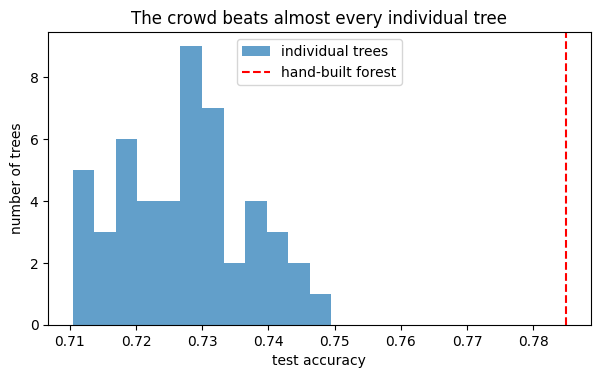

In [6]:
rng = np.random.default_rng(42)
n_trees = 50

hand_trees = []
for i in range(n_trees):
    # 1) bootstrap sample: draw rows with replacement
    idx = rng.integers(0, len(X_train), size=len(X_train))
    X_boot, y_boot = X_train.iloc[idx], y_train.iloc[idx]
    if i == 0:
        unique_share = len(np.unique(idx)) / len(X_train)
        print(f'Share of distinct rows inside the first bootstrap sample: {unique_share:.2f}  (theory: about 0.63)')

    # 2) grow a tree that only considers a random subset of features at every split
    tree = DecisionTreeClassifier(max_features='sqrt', random_state=i)
    tree.fit(X_boot, y_boot)
    hand_trees.append(tree)

# 3) vote: average the probability of churn over all trees
hand_proba = np.mean([t.predict_proba(X_test)[:, 1] for t in hand_trees], axis=0)
hand_pred = (hand_proba >= 0.5).astype(int)

single_accs = [accuracy_score(y_test, t.predict(X_test)) for t in hand_trees]

print()
print(f'Accuracy of the {n_trees} individual trees: average {np.mean(single_accs):.3f}, '
      f'best {np.max(single_accs):.3f}, worst {np.min(single_accs):.3f}')
print('Accuracy of the hand-built forest      :', round(accuracy_score(y_test, hand_pred), 3))
print('ROC-AUC of the hand-built forest       :', round(roc_auc_score(y_test, hand_proba), 3))
print()
print('For comparison, scikit-learn forest    :',
      round(accuracy_score(y_test, models['Random forest (200 trees)'].predict(X_test)), 3),
      '| AUC', round(roc_auc_score(y_test, models['Random forest (200 trees)'].predict_proba(X_test)[:, 1]), 3))

plt.figure(figsize=(7, 3.8))
plt.hist(single_accs, bins=12, alpha=0.7, label='individual trees')
plt.axvline(accuracy_score(y_test, hand_pred), color='red', linestyle='--', label='hand-built forest')
plt.xlabel('test accuracy')
plt.ylabel('number of trees')
plt.title('The crowd beats almost every individual tree')
plt.legend()
plt.show()

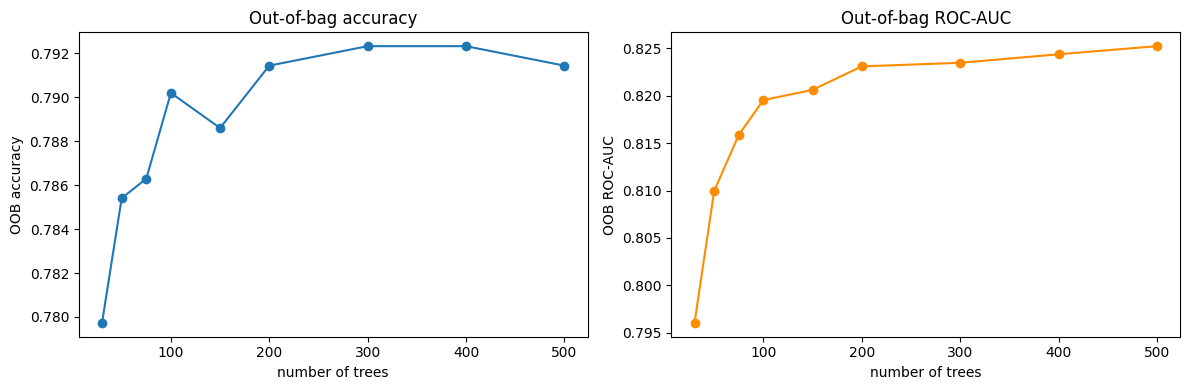

In [7]:
rf_curve = RandomForestClassifier(oob_score=True, warm_start=True, random_state=42, n_jobs=-1)

sizes = [30, 50, 75, 100, 150, 200, 300, 400, 500]
oob_acc, oob_auc = [], []
for n in sizes:
    rf_curve.set_params(n_estimators=n)
    rf_curve.fit(X_train, y_train)          # warm_start: keeps old trees and adds new ones
    oob_acc.append(rf_curve.oob_score_)
    oob_auc.append(roc_auc_score(y_train, rf_curve.oob_decision_function_[:, 1]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(sizes, oob_acc, marker='o')
axes[0].set_xlabel('number of trees')
axes[0].set_ylabel('OOB accuracy')
axes[0].set_title('Out-of-bag accuracy')
axes[1].plot(sizes, oob_auc, marker='o', color='darkorange')
axes[1].set_xlabel('number of trees')
axes[1].set_ylabel('OOB ROC-AUC')
axes[1].set_title('Out-of-bag ROC-AUC')
plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

param_dist = {
    'n_estimators': [200, 300, 400],
    'max_depth': [None, 6, 8, 10, 14, 20],
    'min_samples_leaf': [1, 2, 5, 10, 20],
    'max_features': ['sqrt', 'log2', 0.3, 0.5],
    'class_weight': [None, 'balanced', 'balanced_subsample'],
}

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_dist, n_iter=15, cv=cv, scoring='roc_auc', random_state=42
)
search.fit(X_train, y_train)

best_rf = search.best_estimator_
print('Best settings   :', search.best_params_)
print('Best CV ROC-AUC :', round(search.best_score_, 3))
print()

top = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(5)
print(top[['rank_test_score', 'mean_test_score', 'param_n_estimators', 'param_max_depth',
           'param_min_samples_leaf', 'param_max_features', 'param_class_weight']].round(3).to_string(index=False))

Best settings   : {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 'log2', 'max_depth': 20, 'class_weight': 'balanced_subsample'}
Best CV ROC-AUC : 0.848

 rank_test_score  mean_test_score  param_n_estimators param_max_depth  param_min_samples_leaf param_max_features param_class_weight
               1            0.848                 300              20                      20               log2 balanced_subsample
               2            0.847                 400            None                      10               sqrt balanced_subsample
               3            0.847                 400              10                      10                0.3           balanced
               4            0.846                 400               8                       5                0.3               None
               5            0.846                 400              10                       5               sqrt           balanced


                  model  accuracy  ROC-AUC  churn recall  churn precision
Baseline (always stays)     0.735    0.500         0.000            0.000
   Single decision tree     0.725    0.654         0.503            0.483
Random forest (default)     0.781    0.820         0.495            0.609
  Random forest (tuned)     0.754    0.845         0.791            0.525
    Logistic regression     0.807    0.842         0.567            0.658

Tuned random forest, full report:
              precision    recall  f1-score   support

      Stayed       0.91      0.74      0.82      1035
     Churned       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.77      1409



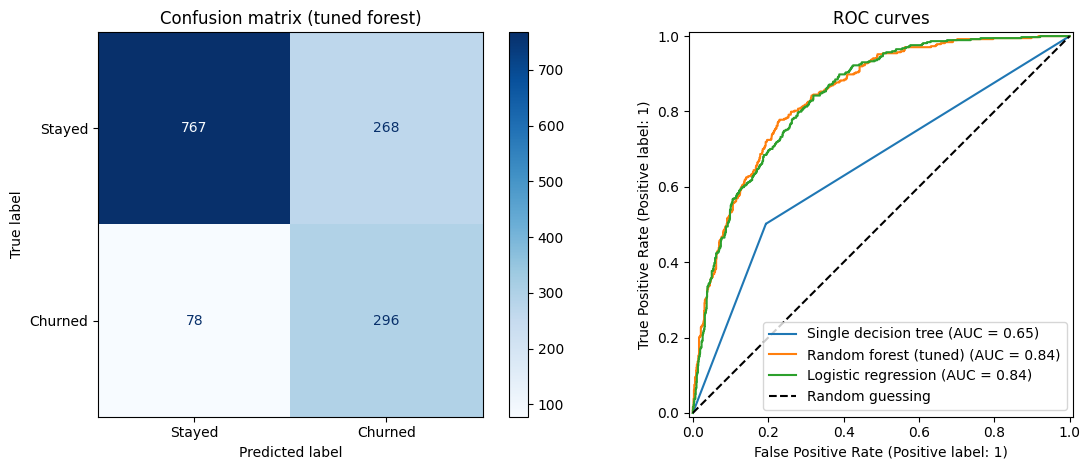

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

compare = {
    'Baseline (always stays)': models['Baseline (always stays)'],
    'Single decision tree': models['Single decision tree'],
    'Random forest (default)': models['Random forest (200 trees)'],
    'Random forest (tuned)': best_rf,
    'Logistic regression': logreg,
}

rows = []
for name, m in compare.items():
    pred_m = m.predict(X_test)
    proba_m = m.predict_proba(X_test)[:, 1]
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred_m),
        'ROC-AUC': roc_auc_score(y_test, proba_m),
        'churn recall': recall_score(y_test, pred_m, zero_division=0),
        'churn precision': precision_score(y_test, pred_m, zero_division=0),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
print('Tuned random forest, full report:')
print(classification_report(y_test, best_rf.predict(X_test), target_names=['Stayed', 'Churned']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, y_test, display_labels=['Stayed', 'Churned'], cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion matrix (tuned forest)')

for name in ['Single decision tree', 'Random forest (tuned)', 'Logistic regression']:
    RocCurveDisplay.from_estimator(compare[name], X_test, y_test, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guessing')
axes[1].legend()
axes[1].set_title('ROC curves')

plt.tight_layout()
plt.show()

In [10]:
proba = best_rf.predict_proba(X_test)[:, 1]

rows = []
for t in np.arange(0.10, 0.71, 0.05):
    flagged = (proba >= t).astype(int)
    rows.append({
        'threshold': round(t, 2),
        'customers flagged': int(flagged.sum()),
        'recall': recall_score(y_test, flagged, zero_division=0),
        'precision': precision_score(y_test, flagged, zero_division=0),
    })
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))

# the highest threshold that still catches at least 75% of the churners
meets_goal = table[table['recall'] >= 0.75]
if len(meets_goal):
    chosen = meets_goal.iloc[-1]
    business_threshold = float(chosen['threshold'])
    print()
    print(f"To catch at least 75% of churners, use a threshold of about {business_threshold:.2f}.")
    print(f"That flags {int(chosen['customers flagged'])} of {len(y_test)} customers, "
          f"and about {chosen['precision'] * 100:.0f}% of them really would churn.")
else:
    business_threshold = 0.30
    print()
    print('No threshold in this table reaches 75% recall; using 0.30 as an example.')

 threshold  customers flagged  recall  precision
      0.10               1113   0.992      0.333
      0.15               1052   0.981      0.349
      0.20                977   0.971      0.372
      0.25                890   0.955      0.401
      0.30                807   0.920      0.426
      0.35                739   0.882      0.447
      0.40                679   0.853      0.470
      0.45                613   0.816      0.498
      0.50                564   0.791      0.525
      0.55                499   0.743      0.557
      0.60                435   0.674      0.579
      0.65                366   0.607      0.620
      0.70                294   0.521      0.663

To catch at least 75% of churners, use a threshold of about 0.50.
That flags 564 of 1409 customers, and about 52% of them really would churn.


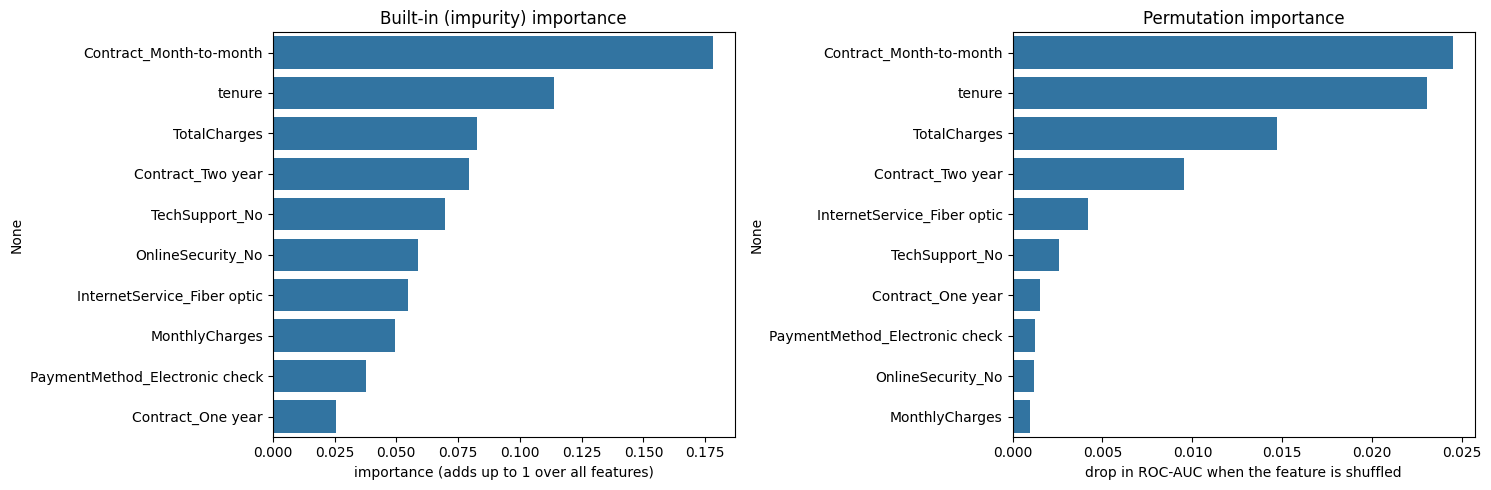

In [11]:
from sklearn.inspection import permutation_importance

imp_impurity = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

perm = permutation_importance(best_rf, X_test, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=42, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_train.columns).sort_values(ascending=False)

top_n = 10
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(x=imp_impurity.head(top_n).values, y=imp_impurity.head(top_n).index, ax=axes[0])
axes[0].set_title('Built-in (impurity) importance')
axes[0].set_xlabel('importance (adds up to 1 over all features)')

sns.barplot(x=imp_perm.head(top_n).values, y=imp_perm.head(top_n).index, ax=axes[1])
axes[1].set_title('Permutation importance')
axes[1].set_xlabel('drop in ROC-AUC when the feature is shuffled')

plt.tight_layout()
plt.show()

In [12]:
def predict_customer(model, details):
    raw = pd.DataFrame([details])
    X_new = encode(raw, columns=X_train.columns)
    p = model.predict_proba(X_new)[0, 1]
    print(f'Probability of churn: {p:.2f}')
    print(f'   at the default 0.50 cut-off      ->', 'WILL LEAVE' if p >= 0.5 else 'stays')
    print(f'   at the business cut-off {business_threshold:.2f}     ->', 'FLAG FOR A RETENTION OFFER' if p >= business_threshold else 'no action')


new_customer = {
    'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
    'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No',
    'StreamingTV': 'Yes', 'StreamingMovies': 'Yes', 'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 89.0, 'TotalCharges': 178.0,
}

loyal_customer = {
    'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes', 'tenure': 60,
    'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'DSL',
    'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes', 'DeviceProtection': 'Yes', 'TechSupport': 'Yes',
    'StreamingTV': 'No', 'StreamingMovies': 'No', 'Contract': 'Two year',
    'PaperlessBilling': 'No', 'PaymentMethod': 'Bank transfer (automatic)',
    'MonthlyCharges': 62.0, 'TotalCharges': 3700.0,
}

print('Customer A: joined 2 months ago, month-to-month, fiber, pays by electronic check')
predict_customer(best_rf, new_customer)
print()
print('Customer B: 5-year customer, two-year contract, DSL with extra services')
predict_customer(best_rf, loyal_customer)

Customer A: joined 2 months ago, month-to-month, fiber, pays by electronic check
Probability of churn: 0.89
   at the default 0.50 cut-off      -> WILL LEAVE
   at the business cut-off 0.50     -> FLAG FOR A RETENTION OFFER

Customer B: 5-year customer, two-year contract, DSL with extra services
Probability of churn: 0.04
   at the default 0.50 cut-off      -> stays
   at the business cut-off 0.50     -> no action
